In [16]:
import os

print(os.getcwd())
print(os.listdir('/content'))

/content
['.config', 'drive', 'social-media-sentiments-analysis', 'sample_data']


In [17]:
!git clone https://github.com/euiedavid/social-media-sentiments-analysis.git

fatal: destination path 'social-media-sentiments-analysis' already exists and is not an empty directory.


In [18]:
!ls /content/social-media-sentiments-analysis/dataset/

sentimentdataset.csv


**Import Libraries**

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

from datetime import datetime

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

print('Successfully imported modules...')

Successfully imported modules...


**Initial Look on the Data**

In [20]:
# create dataframe

file_path = r'/content/social-media-sentiments-analysis/dataset/sentimentdataset.csv'

df = pd.read_csv(file_path)

print('Successfully created dataframe...')

Successfully created dataframe...


In [21]:
# df metadata

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  732 non-null    int64  
 1   Unnamed: 0    732 non-null    int64  
 2   Text          732 non-null    object 
 3   Sentiment     732 non-null    object 
 4   Timestamp     732 non-null    object 
 5   User          732 non-null    object 
 6   Platform      732 non-null    object 
 7   Hashtags      732 non-null    object 
 8   Retweets      732 non-null    float64
 9   Likes         732 non-null    float64
 10  Country       732 non-null    object 
 11  Year          732 non-null    int64  
 12  Month         732 non-null    int64  
 13  Day           732 non-null    int64  
 14  Hour          732 non-null    int64  
dtypes: float64(2), int64(6), object(7)
memory usage: 85.9+ KB


In [22]:
# first fop rows
print('Top 5 Rows: ')
display(df.head())
print('\nLast 5 Rows:')
display(df.tail())

Top 5 Rows: 


,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19



Last 5 Rows:


,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
727,728,732,Collaborating on a science project that receiv...,Happy,2017-08-18 18:20:00,ScienceProjectSuccessHighSchool,Facebook,#ScienceFairWinner #HighSchoolScience,20.0,39.0,UK,2017,8,18,18
728,729,733,Attending a surprise birthday party organized ...,Happy,2018-06-22 14:15:00,BirthdayPartyJoyHighSchool,Instagram,#SurpriseCelebration #HighSchoolFriendship,25.0,48.0,USA,2018,6,22,14
729,730,734,Successfully fundraising for a school charity ...,Happy,2019-04-05 17:30:00,CharityFundraisingTriumphHighSchool,Twitter,#CommunityGiving #HighSchoolPhilanthropy,22.0,42.0,Canada,2019,4,5,17
730,731,735,"Participating in a multicultural festival, cel...",Happy,2020-02-29 20:45:00,MulticulturalFestivalJoyHighSchool,Facebook,#CulturalCelebration #HighSchoolUnity,21.0,43.0,UK,2020,2,29,20
731,732,736,Organizing a virtual talent show during challe...,Happy,2020-11-15 15:15:00,VirtualTalentShowSuccessHighSchool,Instagram,#VirtualEntertainment #HighSchoolPositivity,24.0,47.0,USA,2020,11,15,15


In [23]:
# return each number of unique values per column
df.nunique().sort_values(ascending=False)

,0
Unnamed: 0.1,732
Unnamed: 0,732
Text,707
Hashtags,697
User,685
Timestamp,683
Sentiment,279
Country,115
Likes,38
Day,31


In [24]:
# descriptive statisticsfor num cols
df.describe().round(2).map(lambda x: f'{x:g}')

,Unnamed: 0.1,Unnamed: 0,Retweets,Likes,Year,Month,Day,Hour
count,732,732,732,732,732,732,732,732
mean,366.46,369.74,21.51,42.9,2020.47,6.12,15.5,15.52
std,211.51,212.43,7.06,14.09,2.8,3.41,8.47,4.11
min,0,0,5,10,2010,1,1,0
25%,183.75,185.75,17.75,34.75,2019,3,9,13
50%,366.5,370.5,22,43,2021,6,15,16
75%,549.25,553.25,25,50,2023,9,22,19
max,732,736,40,80,2023,12,31,23


In [25]:
# descriptive statistics for cat cols
df.describe(include='O').T

,count,unique,top,freq
Text,732,707,"A compassionate rain, tears of empathy fallin...",3
Sentiment,732,279,Positive,44
Timestamp,732,683,2019-04-05 17:30:00,3
User,732,685,WinterWarmth,3
Platform,732,4,Instagram,258
Hashtags,732,697,#Hopeful #SeedsOfOptimism,3
Country,732,115,USA,59


**Data Quality**

In [26]:
# to prevent alteration
data = df.copy()

print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  732 non-null    int64  
 1   Unnamed: 0    732 non-null    int64  
 2   Text          732 non-null    object 
 3   Sentiment     732 non-null    object 
 4   Timestamp     732 non-null    object 
 5   User          732 non-null    object 
 6   Platform      732 non-null    object 
 7   Hashtags      732 non-null    object 
 8   Retweets      732 non-null    float64
 9   Likes         732 non-null    float64
 10  Country       732 non-null    object 
 11  Year          732 non-null    int64  
 12  Month         732 non-null    int64  
 13  Day           732 non-null    int64  
 14  Hour          732 non-null    int64  
dtypes: float64(2), int64(6), object(7)
memory usage: 85.9+ KB
None


In [27]:
# drop columns
data = data.drop(columns=['Unnamed: 0.1', 'Unnamed: 0'])

row, col = data.shape
print(f'Total Number of Rows: {row}')
print(f'Total Number of Columns: {col}')
print('Successfully dropped columns...')

Total Number of Rows: 732
Total Number of Columns: 13
Successfully dropped columns...


In [28]:
# check if df has duplicates
has_duplicates = data.duplicated().any()
print(f'Are there duplicates in the dataset?: {has_duplicates}')

duplicate_count = data.duplicated().sum()
print(f'Number of duplicates: {duplicate_count}')

Are there duplicates in the dataset?: True
Number of duplicates: 20


In [29]:
data[data.duplicated(subset=['Text'], keep=False)]

,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
264,"A compassionate rain, tears of empathy fallin...",Compassionate,2021-07-01 12:10:00,RainNurturer,Facebook,#Compassionate #TearsOfEmpathy,21.0,42.0,Canada,2021,7,1,12
265,"Proudly scaling the peaks of achievement, a m...",Proud,2020-01-05 08:45:00,PeakConqueror,Twitter,#Proud #ScalingPeaks,23.0,46.0,USA,2020,1,5,8
266,"Embraced by the hopeful dawn, a gardener sowi...",Hopeful,2022-07-17 06:15:00,DawnGardener,Instagram,#Hopeful #SeedsOfOptimism,14.0,28.0,UK,2022,7,17,6
267,"A playful escapade in the carnival of life, c...",Playful,2018-08-22 17:20:00,CarnivalDreamer,Facebook,#Playful #CarnivalEscapade,24.0,48.0,Australia,2018,8,22,17
268,"Floating on clouds of inspiration, an artist ...",Inspired,2021-12-08 14:30:00,SkyArtist,Twitter,#Inspired #CloudsOfCreativity,18.0,36.0,India,2021,12,8,14
269,"Navigating the river of contentment, a serene...",Contentment,2019-04-27 09:50:00,RiverNavigator,Instagram,#Contentment #TranquilWaters,20.0,40.0,Canada,2019,4,27,9
270,"With empathy as a lantern, wandering through ...",Empathetic,2023-09-03 21:40:00,LanternWanderer,Facebook,#Empathetic #LanternOfCompassion,16.0,32.0,USA,2023,9,3,21
271,"A free spirit soaring on the wings of dreams,...",Free-spirited,2020-06-10 10:05:00,DreamSoarer,Twitter,#FreeSpirit #WingsOfDreams,22.0,44.0,UK,2020,6,10,10
272,"Bathed in the golden hues of gratefulness, a ...",Grateful,2022-04-01 18:30:00,SunsetAdmirer,Instagram,#Grateful #GoldenHues,19.0,38.0,Australia,2022,4,1,18
273,"Confident strides in the dance of life, a bal...",Confident,2021-01-15 13:00:00,DanceStrider,Facebook,#Confident #DanceOfLife,23.0,46.0,Canada,2021,1,15,13


In [30]:
# drop duplicates
data = data.drop_duplicates()

print("You have successfully dropped duplicates in the dataset...\n")
print('Count of rows after removing duplicates', len(data))
print('Count of duplicates in the dataset:', data.duplicated().sum())

You have successfully dropped duplicates in the dataset...

Count of rows after removing duplicates 712
Count of duplicates in the dataset: 0


In [31]:
# Check for missing values
any_missing = data.isnull().any().sort_values(ascending=False)
print("Missing value status per column:")
print(any_missing)

missing_count = data.isnull().sum().sort_values(ascending=False)
print("\nMissing value count per column:")
print(missing_count)

Missing value status per column:
Text         False
Sentiment    False
Timestamp    False
User         False
Platform     False
Hashtags     False
Retweets     False
Likes        False
Country      False
Year         False
Month        False
Day          False
Hour         False
dtype: bool

Missing value count per column:
Text         0
Sentiment    0
Timestamp    0
User         0
Platform     0
Hashtags     0
Retweets     0
Likes        0
Country      0
Year         0
Month        0
Day          0
Hour         0
dtype: int64


In [32]:
# inspect data types
df.dtypes

,0
Unnamed: 0.1,int64
Unnamed: 0,int64
Text,object
Sentiment,object
Timestamp,object
User,object
Platform,object
Hashtags,object
Retweets,float64
Likes,float64


In [33]:
# convert timestamp to datetime
data['Timestamp'] = pd.to_datetime(data['Timestamp'])

# inspect conversion
data['Timestamp'].dtype

dtype('<M8[ns]')

In [34]:
# address inconsistencies
cols = data[['Sentiment', 'Country', 'Platform']]

for col in cols:
  data[col] = data[col].str.strip()

  print(f'{col}:')
  print(data[col].value_counts(dropna=False).to_string(header=False))
  print("=====" * 10)

Sentiment:
Positive                45
Joy                     44
Excitement              37
Contentment             18
Neutral                 18
Gratitude               17
Curiosity               16
Serenity                15
Happy                   14
Despair                 11
Nostalgia               11
Awe                      9
Grief                    9
Sad                      9
Acceptance               8
Loneliness               8
Embarrassed              8
Confusion                8
Determination            7
Euphoria                 7
Enthusiasm               7
Pride                    7
Elation                  7
Ambivalence              6
Hopeful                  6
Frustration              6
Numbness                 6
Surprise                 6
Melancholy               6
Regret                   6
Indifference             6
Inspiration              6
Hate                     6
Bad                      6
Frustrated               5
Hope                     5
Empowerment      

## **Exploratory Data Analysis**

### **Engagement Metrics Analysis and Outlier Investigation**

**Observations:**

- The average engagement per post is 64.48, with a standard deviation of 21.34, indicating some variation in engagement levels.
- The median engagement is 65, meaning approximately half of the posts have 65 or fewer interactions, while the other half have 65 or more.
- The middle 50% of posts have total engagement values ranging from 52 to 75.
- Total engagement ranges from 15 to 120 interactions, showing a difference of 105 between the lowest and highest recorded values.
- The distribution appears relatively symmetrical, as the mean (64.48) and median (65) are close to each other. This observation can be further assessed using the histogram.

In [35]:
# inspect numerical cols
data[['Retweets', 'Likes']].describe().round(2).map(lambda x: f'{x:g}').T

,count,mean,std,min,25%,50%,75%,max
Retweets,712,21.54,7.12,5,17.75,22,25,40
Likes,712,42.97,14.22,10,34.75,43,50,80


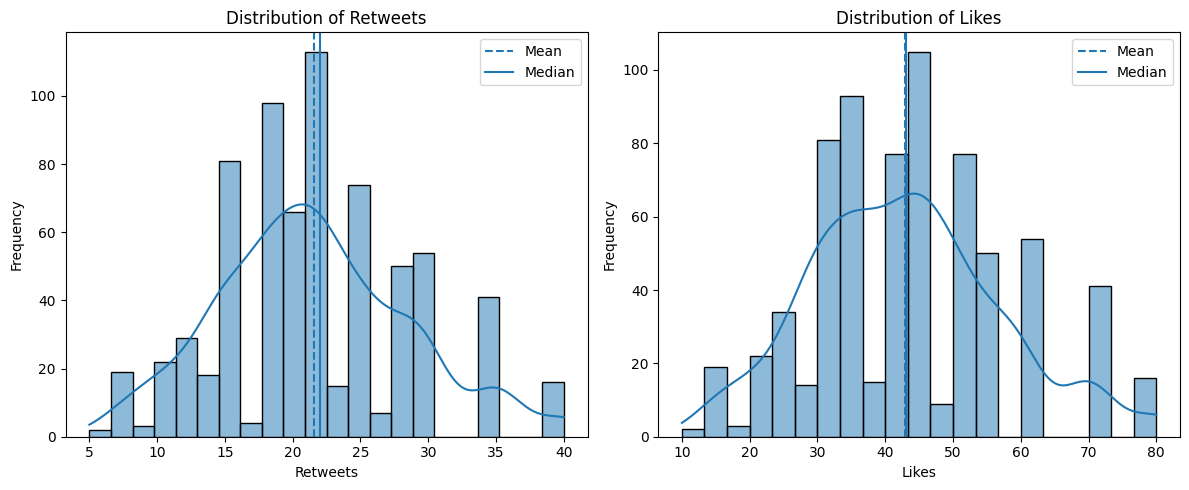

In [36]:
# Plot histograms
num_cols = data[['Retweets', 'Likes']]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, num_cols):

    sns.histplot(data=data, x=col, kde=True, ax=ax)

    ax.axvline(data[col].mean(), linestyle='--', label='Mean')
    ax.axvline(data[col].median(), linestyle='-', label='Median')

    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
    ax.legend()

plt.tight_layout()
plt.show()

In [37]:
# inspect for outliers
def main():

  identify_outliers()

def identify_outliers():

  q1 = num_cols.quantile(0.25)
  q3 = num_cols.quantile(0.75)

  iqr = q3 - q1

  lower_limit = q1 - 1.5 * iqr
  upper_limit = q3 + 1.5 * iqr

  for col in num_cols:

    lower_outliers = num_cols[col][num_cols[col] < lower_limit[col]]
    upper_outliers = num_cols[col][num_cols[col] > upper_limit[col]]


    print(f'{col}:')

    print(f'Number of Lower Outliers: {len(lower_outliers)}')
    print(f'Lower Limit: {lower_limit[col]}')
    print(f'Lower Outliers: {lower_outliers.tolist()}')


    print(f'Number of Upper Outliers: {len(upper_outliers)}')
    print(f'Upper Limit: {upper_limit[col]}')
    print(f'Upper Outliers: {upper_outliers.tolist()}')


    print("=====" * 25)

main()

Retweets:
Number of Lower Outliers: 2
Lower Limit: 6.875
Lower Outliers: [5.0, 5.0]
Number of Upper Outliers: 16
Upper Limit: 35.875
Upper Outliers: [40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0]
Likes:
Number of Lower Outliers: 2
Lower Limit: 11.875
Lower Outliers: [10.0, 10.0]
Number of Upper Outliers: 16
Upper Limit: 72.875
Upper Outliers: [80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0]


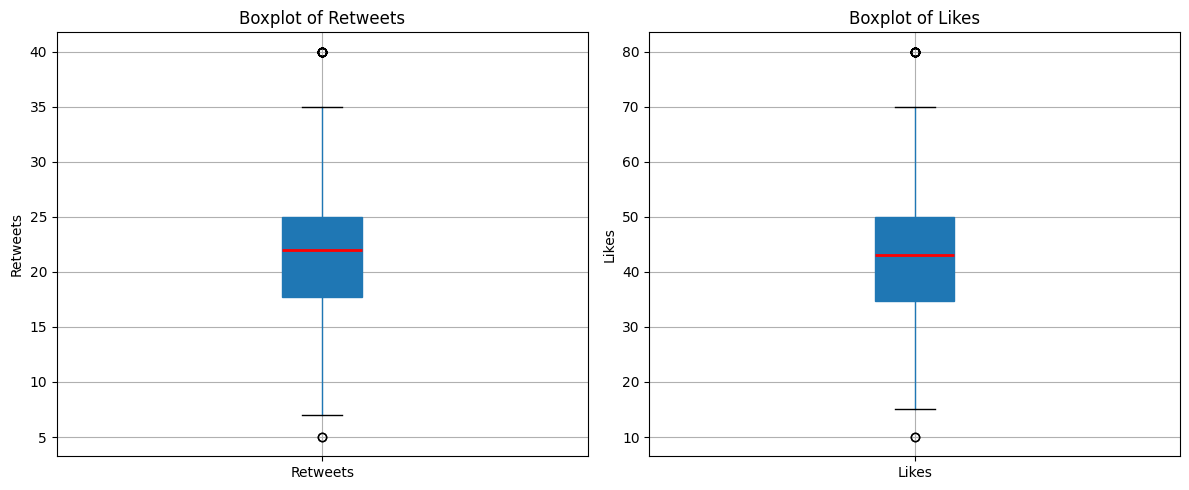

In [38]:
# plot boxplot

fig, axes = plt.subplots(1, 2, figsize=(12,5))

for ax, col in zip(axes, num_cols):

  data.boxplot(
               column=[col],
               ax=ax,
               patch_artist=True,
               medianprops={
                   'color': 'red',
                   'linewidth': 2
                   }
               )

  ax.set_title(f'Boxplot of {col}')
  ax.set_ylabel(col)

plt.tight_layout()
plt.show()

In [39]:
# create a new column combining likes and retweets
data['Total Engagement'] = data['Likes'] + data['Retweets']

# inspect new column
data.head()

,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour,Total Engagement
0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12,45.0
1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8,15.0
2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15,60.0
3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18,23.0
4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19,37.0


In [40]:
# inspect descriptive statistics for the total engagement
data['Total Engagement'].describe().round(2).map(lambda x: f'{x:g}')

,Total Engagement
count,712
mean,64.51
std,21.33
min,15
25%,52.5
50%,65
75%,75
max,120


In [41]:
data['Total Engagement'].value_counts()

,count
Total Engagement,
67.0,95
53.0,76
75.0,72
45.0,72
60.0,61
90.0,54
83.0,50
105.0,41
37.0,23


In [42]:
outliers = data[
    (data['Total Engagement'] < 17.5) |
    (data['Total Engagement'] > 109.5)
]

outliers

,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour,Total Engagement
1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8,15.0
163,Suffering from despair after another setback....,Despair,2021-03-10 08:30:00,StrugglingSoul,Twitter,#Despair #Struggle,5.0,10.0,USA,2021,3,10,8,15.0
335,Thrilled to witness the grandeur of a cultural...,Thrill,2020-09-15 14:45:00,CultureEnthusiast,Instagram,#Thrill #CulturalCelebration,40.0,80.0,India,2020,9,15,14,120.0
345,Motivated to achieve fitness goals after an in...,Motivation,2022-02-28 07:15:00,FitnessJunkie,Facebook,#Motivation #FitnessGoals,40.0,80.0,Australia,2022,2,28,7,120.0
355,Anticipation for an upcoming adventure in an e...,Anticipation,2022-07-25 10:00:00,Wanderlust,Twitter,#Anticipation #AdventureAwaits,40.0,80.0,India,2022,7,25,10,120.0
368,Elation over discovering a rare book in a quai...,Elation,2018-09-22 16:30:00,Bookworm,Instagram,#Elation #RareBookDiscovery,40.0,80.0,USA,2018,9,22,16,120.0
382,A sense of wonder at the vastness of the cosmo...,Wonder,2018-07-08 23:00:00,CosmosExplorer,Instagram,#Wonder #StargazingAdventure,40.0,80.0,South Africa,2018,7,8,23,120.0
402,Awe-inspired by the vastness of the cosmos on ...,Wonder,2018-07-08 23:00:00,CosmosExplorer,Instagram,#Wonder #StargazingAdventure,40.0,80.0,South Africa,2018,7,8,23,120.0
432,"Heartache deepens, a solitary journey through ...",Despair,2022-08-18 22:00:00,SolitaryDescent,Instagram,#Despair #AbyssOfHeartache,40.0,80.0,South Africa,2022,8,18,22,120.0
470,"Dancing on sunshine, each step a celebration o...",Joy,2021-08-20 15:45:00,SunshineDancer,Instagram,#Joy #SimpleMoments,40.0,80.0,USA,2021,8,20,15,120.0


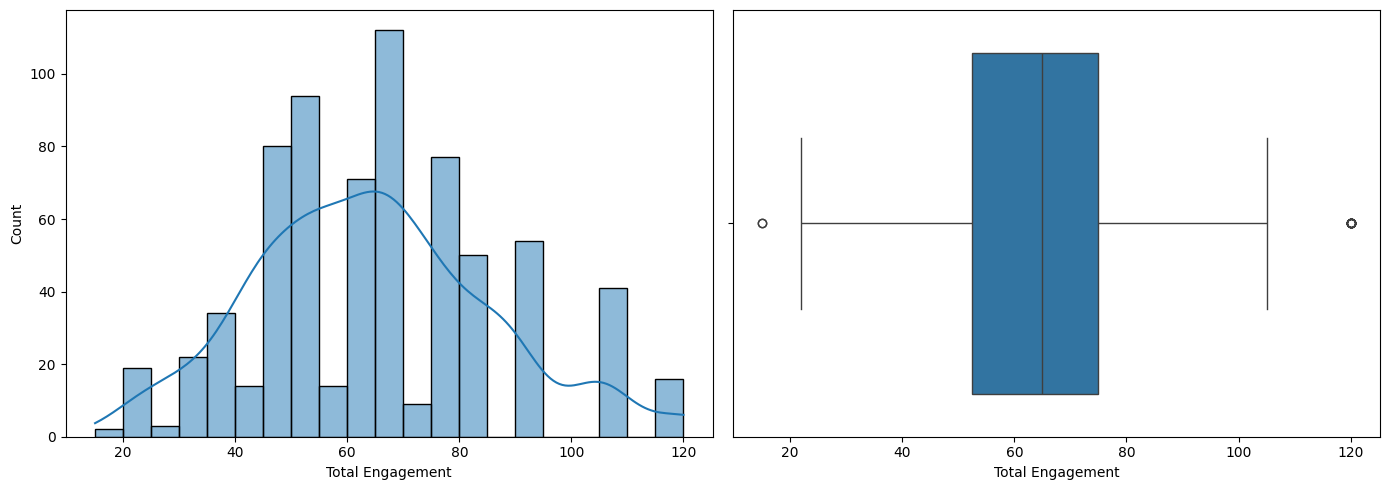

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=data, x='Total Engagement', kde=True, ax=axes[0])
sns.boxplot(data=data, x='Total Engagement', ax=axes[1])

plt.tight_layout()
plt.show()

### **Sentiment Distribution Analysis**

**Observations:**

- The dataset contains 191 unique sentiment labels, some of which have overlapping or semantically similar meanings. These labels were retained in their original form to preserve the dataset's classifications and avoid introducing subjective grouping assumptions.
- Positive is the most frequent sentiment, with 45 posts, closely followed by Joy (44) and Excitement (37).
- Contentment and Neutral are tied at 18 posts each.
- The remaining categories have considerably lower frequencies, with Determination and Euphoria appearing seven times each among the top 20.
- The distribution indicates that sentiment labels are highly fragmented, with many categories appearing only a few times.

In [44]:
sentiment_count = data['Sentiment'].nunique()
print(f'Number of unique values in the Sentiment column: {sentiment_count}')

Number of unique values in the Sentiment column: 191


In [45]:
# check frequency and percentage of each sentiment

sentiment_counts = pd.concat([
    data['Sentiment'].value_counts(),
    data['Sentiment'].value_counts(normalize=True)
], axis=1)

sentiment_counts.columns = ['Frequency', 'Percentage (%)']

sentiment_counts

,Frequency,Percentage (%)
Sentiment,,
Positive,45,0.063202
Joy,44,0.061798
Excitement,37,0.051966
Contentment,18,0.025281
Neutral,18,0.025281
Gratitude,17,0.023876
Curiosity,16,0.022472
Serenity,15,0.021067
Happy,14,0.019663


In [46]:
# check how many sentiment categories have a particular number of posts
sentiment_counts.value_counts()

,,count
Frequency,Percentage (%),
1,0.001404,81
2,0.002809,31
3,0.004213,24
4,0.005618,14
6,0.008427,11
5,0.007022,7
7,0.009831,5
8,0.011236,4
9,0.012640,3


In [47]:
data['Sentiment'].value_counts().head(20)

,count
Sentiment,
Positive,45
Joy,44
Excitement,37
Contentment,18
Neutral,18
Gratitude,17
Curiosity,16
Serenity,15
Happy,14


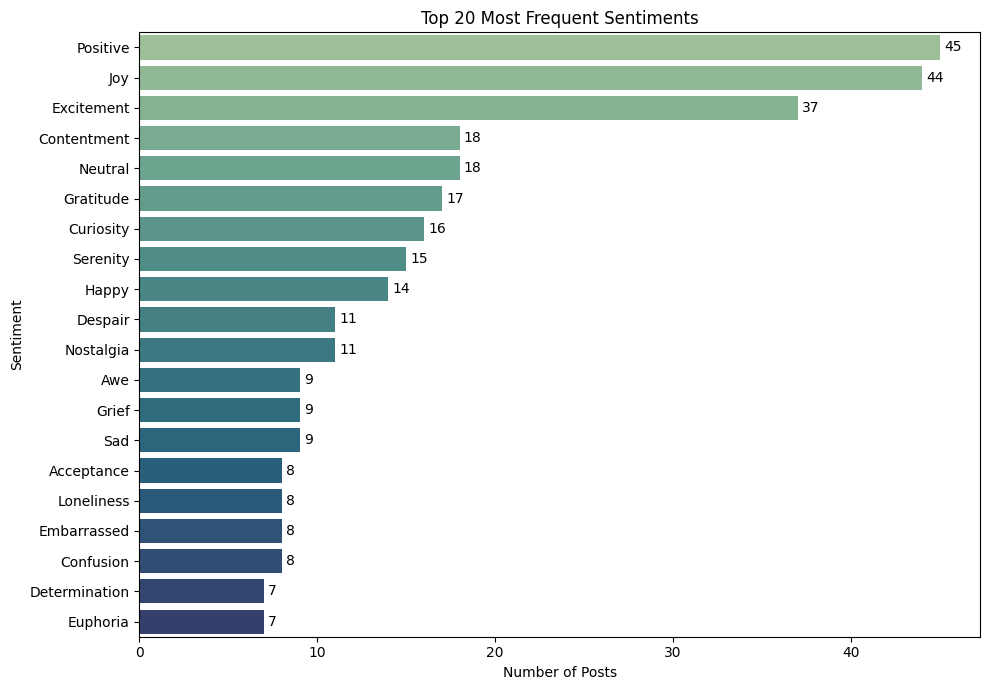

In [48]:
# Get top 20 sentiment categories
top_sentiments = data['Sentiment'].value_counts().head(20)

# Plot horizontal bar chart
plt.figure(figsize=(10, 7))

ax = sns.barplot(
    x=top_sentiments.values,
    y=top_sentiments.index,
    palette='crest'
)

# add bar labels
for container in ax.containers:
  ax.bar_label(
      container,
      padding=3
  )

plt.title('Top 20 Most Frequent Sentiments')
plt.xlabel('Number of Posts')
plt.ylabel('Sentiment')

plt.tight_layout()
plt.show()

### **Sentiment Distribution Across Platforms Analysis**

**Observations:**

**Facebook**
- Joy is the most frequent sentiment, with 20 posts, followed by Positive (16) and Excitement (11).
- Contentment, Neutral, Gratitude, and Curiosity each have 6 posts, while Serenity has 5. Happy and Despair each have 4 posts.
- Joy, Positive, and Excitement are the three most frequently occurring sentiment labels on Facebook.

**Instagram**
- Positive is the most frequent sentiment, with 16 posts, followed by Joy (14) and Excitement (13).
- Contentment, Neutral, Curiosity, and Happy each have 6 posts. Gratitude, Serenity, and Despair each have 4 posts.
- Similar to Facebook, Positive, Joy, and Excitement are the three most frequent sentiment labels on Instagram.

**Twitter**
- Positive and Excitement are tied as the most frequent sentiments, with 13 posts each, followed by Joy (10).
- Gratitude follows with 7 posts. Contentment, Neutral, and Serenity each have 6 posts.
- Curiosity and Happy each have 4 posts, while Despair has 3.


Across all three platforms, Positive, Joy, and Excitement consistently rank among the most frequent sentiment labels. However, their relative frequencies differ: Facebook has the highest Joy count, while Instagram has the highest Positive count, and Twitter has a tie between Positive and Excitement.

In [49]:
# count sentiment categories across platforms
platform_sentiments = data.groupby(
    ['Platform', 'Sentiment']
).size().unstack(fill_value=0)

platform_sentiments

Sentiment,Acceptance,Accomplishment,Admiration,Adoration,Adrenaline,Adventure,Affection,Amazement,Ambivalence,Amusement,Anger,Anticipation,Anxiety,Appreciation,Apprehensive,Arousal,ArtisticBurst,Awe,Bad,Betrayal,Bitter,Bitterness,Bittersweet,Blessed,Boredom,Breakthrough,Calmness,Captivation,Celebration,Celestial Wonder,Challenge,Charm,Colorful,Compassion,Compassionate,Confidence,Confident,Confusion,Connection,Contemplation,Contentment,Coziness,Creative Inspiration,Creativity,Culinary Adventure,CulinaryOdyssey,Curiosity,Darkness,Dazzle,Desolation,Despair,Desperation,Determination,Devastated,Disappointed,Disappointment,Disgust,Dismissive,DreamChaser,Ecstasy,Elation,Elegance,Embarrassed,Emotion,EmotionalStorm,Empathetic,Empowerment,Enchantment,Energy,Engagement,Enjoyment,Enthusiasm,Envious,Envisioning History,Envy,Euphoria,Excitement,Exhaustion,Exploration,Fear,Fearful,FestiveJoy,Free-spirited,Freedom,Friendship,Frustrated,Frustration,Fulfillment,Grandeur,Grateful,Gratitude,Grief,Happiness,Happy,Harmony,Hate,Heartache,Heartbreak,Heartwarming,Helplessness,Hope,Hopeful,Hypnotic,Iconic,Imagination,Immersion,Indifference,InnerJourney,Inspiration,Inspired,Intimidation,Intrigue,Isolation,Jealous,Jealousy,Journey,Joy,Joy in Baking,JoyfulReunion,Kind,Kindness,Loneliness,Loss,LostLove,Love,Marvel,Melancholy,Melodic,Mesmerizing,Mindfulness,Miscalculation,Mischievous,Motivation,Nature's Beauty,Negative,Neutral,Nostalgia,Numbness,Obstacle,Ocean's Freedom,Optimism,Overjoyed,Overwhelmed,Pensive,Playful,PlayfulJoy,Positive,Positivity,Pressure,Pride,Proud,Radiance,Reflection,Regret,Rejuvenation,Relief,Renewed Effort,Resentment,Resilience,Reverence,Romance,Ruins,Runway Creativity,Sad,Sadness,Satisfaction,Serenity,Shame,Solace,Solitude,Sorrow,Spark,Success,Suffering,Surprise,Suspense,Sympathy,Tenderness,Thrill,Thrilling Journey,Touched,Tranquility,Triumph,Vibrancy,Whimsy,Whispers of the Past,Winter Magic,Wonder,Wonderment,Yearning,Zest
Platform,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Facebook,4,3,0,0,1,0,0,0,2,1,0,0,1,0,0,0,0,5,2,2,2,2,0,0,1,0,1,0,0,1,1,0,0,2,1,0,1,2,0,0,6,0,0,0,0,0,6,1,1,2,4,0,3,0,0,0,0,0,0,1,2,1,2,1,0,1,0,1,0,1,2,2,1,0,1,3,11,0,0,0,1,1,0,0,0,2,1,2,0,1,6,6,1,4,1,2,0,0,0,0,2,1,1,0,1,0,3,0,2,1,1,0,0,1,1,0,20,0,0,1,1,2,0,1,0,0,2,0,0,0,0,0,1,0,0,6,4,1,0,1,0,0,3,0,2,1,16,0,1,1,0,2,1,1,0,0,0,1,1,0,0,0,0,3,2,0,5,2,1,0,0,1,0,1,1,1,0,2,1,0,0,1,1,0,0,0,1,0,0,1,0
Instagram,2,0,2,0,0,0,2,0,2,2,0,2,1,0,1,2,0,3,2,2,0,2,1,1,2,0,0,0,1,0,0,0,1,2,1,1,1,4,1,1,6,1,0,1,1,0,6,0,0,0,4,1,1,2,0,0,2,2,0,0,3,0,3,1,1,1,3,3,0,0,0,4,0,0,1,4,13,1,1,2,0,0,1,0,1,2,3,0,1,1,4,2,2,6,2,2,1,1,1,1,1,3,0,0,0,0,2,1,1,0,0,0,2,0,1,1,14,1,1,0,0,2,1,0,0,1,2,0,0,1,1,1,0,1,1,6,4,3,0,0,1,0,1,0,1,0,16,1,0,3,0,0,1,2,0,1,0,1,0,2,1,0,1,3,0,0,4,0,0,1,1,0,1,0,4,0,1,0,2,0,1,1,0,1,2,0,0,3,0,1,1
Twitter,2,0,2,2,0,3,0,1,2,0,2,1,0,1,1,2,1,1,2,1,1,1,0,0,1,1,3,2,0,0,0,1,0,0,1,0,0,2,0,1,6,0,1,2,0,1,4,0,0,2,3,0,3,1,2,2,3,1,1,0,2,0,3,0,0,0,2,0,1,0,0,1,2,1,0,0,13,0,1,0,2,0,1,1,0,1,2,2,0,1,7,1,2,4,0,2,0,2,0,1,2,2,0,1,0,1,1,0,3,2,1,1,0,2,1,0,10,0,0,2,0,4,1,0,3,0,2,1,1,0,0,1,0,0,3,6,3,2,1,0,0,1,0,1,0,0,13,0,0,3,2,0,2,3,1,0,1,1,1,2,0,1,0,3,0,3,6,1,0,0,1,0,0,0,1,0,0,2,1,1,0,0,0,0,0,1,0,0,1,0,1


In [50]:
# Get the top 10 sentiments
top_10 = data['Sentiment'].value_counts().head(10).index

# Filter the cross-tabulation
platform_sentiments_top10 = platform_sentiments[top_10]

platform_sentiments_top10

Sentiment,Positive,Joy,Excitement,Contentment,Neutral,Gratitude,Curiosity,Serenity,Happy,Despair
Platform,,,,,,,,,,
Facebook,16,20,11,6,6,6,6,5,4,4
Instagram,16,14,13,6,6,4,6,4,6,4
Twitter,13,10,13,6,6,7,4,6,4,3


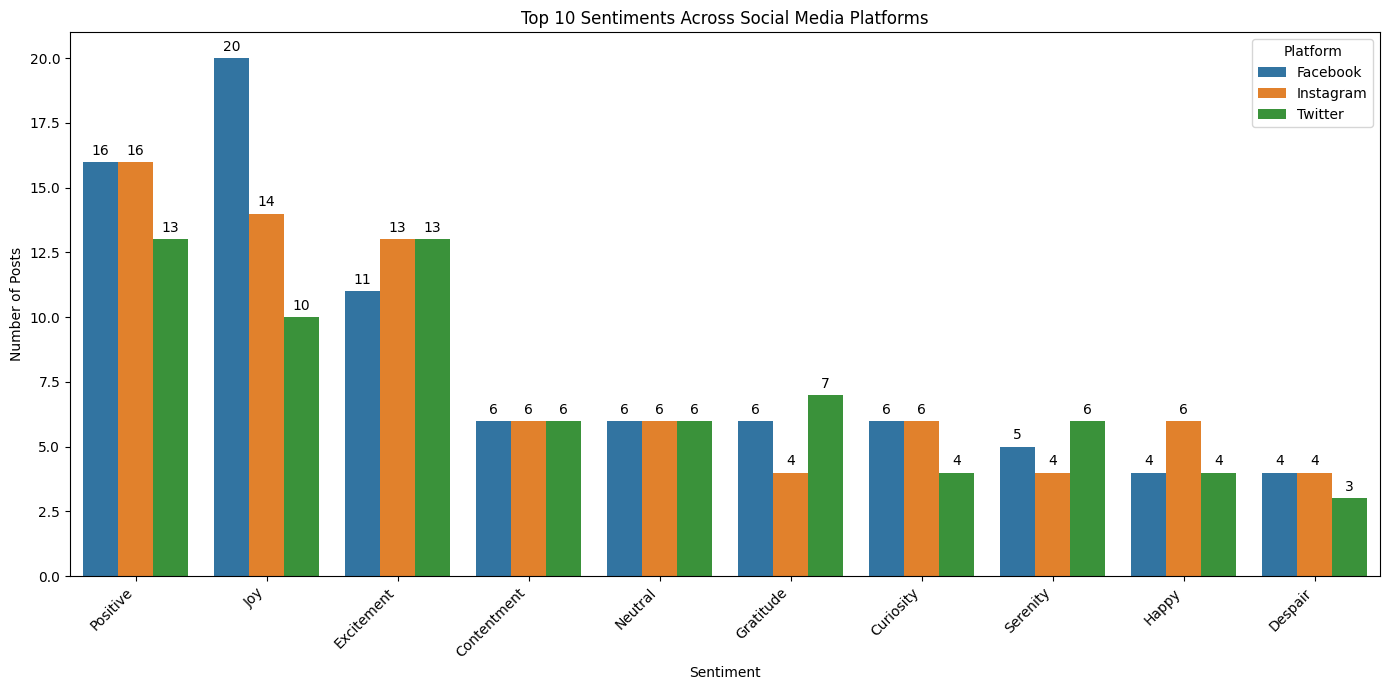

In [54]:
# # Reset index
# platform_sentiments_top10 = platform_sentiments_top10.reset_index()

# # Reshape the DataFrame
# platform_sentiments_melted = platform_sentiments_top10.melt(
#     id_vars='Platform',
#     var_name='Sentiment',
#     value_name='Frequency'
# )

# # Plot grouped bar chart
# plt.figure(figsize=(14, 7))

# ax = sns.barplot(
#     data=platform_sentiments_melted,
#     x='Sentiment',
#     y='Frequency',
#     hue='Platform'
# )

# # Add labels to all bars
# for container in ax.containers:
#     ax.bar_label(
#         container,
#         padding=3
#     )

# plt.title('Top 10 Sentiments Across Social Media Platforms')
# plt.xlabel('Sentiment')
# plt.ylabel('Number of Posts')
# plt.xticks(rotation=45, ha='right')
# plt.legend(title='Platform')
# plt.tight_layout()
# plt.show()

### **Engagement per Platform Analysis**

**Observations:**

- Instagram leads in both post volume (252 posts) and total engagement (17,077). It also records the highest average engagement per post at 67.77.



- Twitter ranks second in total engagement (14,761), despite having fewer posts than Instagram.



- Facebook has the lowest post count (224) and total engagement (14,092). However, its average engagement (62.91) is slightly higher than Twitter's (62.55).

In [55]:
# calculate average engagement per platform
platform_engagement = data.groupby('Platform')['Total Engagement'].mean()

platform_engagement.sort_values(ascending=False).round(2)

,Total Engagement
Platform,
Instagram,67.77
Facebook,62.91
Twitter,62.55


In [56]:
# calculate post count and total engagement per platform
platform_summary = data.groupby('Platform').agg(
    Post_Count=('Total Engagement', 'count'),
    Total_Engagement=('Total Engagement', 'sum'),
    Average_Engagement=('Total Engagement', 'mean')
)

platform_summary.sort_values(
    by='Total_Engagement',
    ascending=False
)

,Post_Count,Total_Engagement,Average_Engagement
Platform,,,
Instagram,252,17077.0,67.765873
Twitter,236,14761.0,62.546610
Facebook,224,14092.0,62.910714


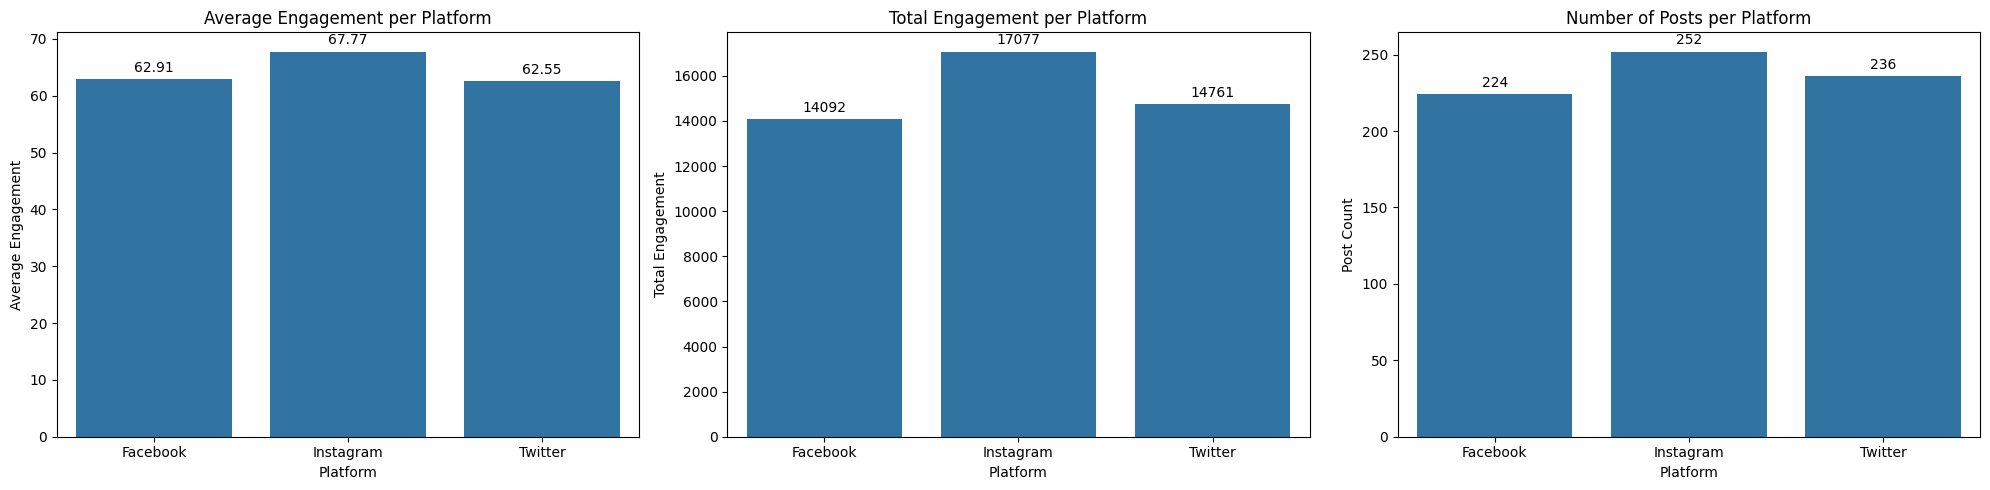

In [57]:
# Create subplots (1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Average Engagement
sns.barplot(
    data=platform_summary,
    x=platform_summary.index,
    y='Average_Engagement',
    ax=axes[0]
)

for container in axes[0].containers:
    axes[0].bar_label(container, padding=3, fmt='%.2f')

axes[0].set_title('Average Engagement per Platform')
axes[0].set_xlabel('Platform')
axes[0].set_ylabel('Average Engagement')


# 2. Total Engagement
sns.barplot(
    data=platform_summary,
    x=platform_summary.index,
    y='Total_Engagement',
    ax=axes[1]
)

for container in axes[1].containers:
    axes[1].bar_label(container, padding=3, fmt='%.0f')

axes[1].set_title('Total Engagement per Platform')
axes[1].set_xlabel('Platform')
axes[1].set_ylabel('Total Engagement')


# 3. Post Count
sns.barplot(
    data=platform_summary,
    x=platform_summary.index,
    y='Post_Count',
    ax=axes[2]
)

for container in axes[2].containers:
    axes[2].bar_label(container, padding=3, fmt='%.0f')

axes[2].set_title('Number of Posts per Platform')
axes[2].set_xlabel('Platform')
axes[2].set_ylabel('Post Count')


# Adjust layout
plt.tight_layout()
plt.show()

### **Engagement Trends Over Time**

1. Engagement by Hour

Determine which hours have the highest average engagement.

Suggested visualization: Bar chart.



2. Engagement by Day

Compare engagement across different days of the month.

Suggested visualization: Line chart.



3. Engagement by Month

Examine how average engagement changes across months.

Suggested visualization: Line chart.

### **Engagement by Hour**


**Observations:**

- Highest engagement: 11:00 PM records the highest average engagement (85.00) across 7 posts, followed by 5:00 AM (83.00) from just 1 post.

- Lowest engagement: Midnight (12:00 AM) has the lowest average engagement at 53.00, based on 1 post.

- Daily fluctuations: Engagement fluctuates throughout the day, with generally higher averages during the evening, particularly between 8:00 PM and 11:00 PM.

- Post volume vs. engagement: 2:00 PM has the highest post volume (92) but an average engagement of only 62.66. More posts do not necessarily mean higher average engagement.


Note: Interpret averages from hours with very few posts cautiously, as they may not represent consistent engagement patterns.

In [69]:
# Calculate average engagement per hour
hourly_engagement = data.groupby('Hour').agg(
    Post_Count=('Total Engagement', 'count'),
    Average_Engagement=('Total Engagement', 'mean')
)

# Sort by hour
hourly_engagement = hourly_engagement.sort_index()

# Round average engagement to 2 decimal places
hourly_engagement['Average_Engagement'] = hourly_engagement['Average_Engagement'].round(2)

# sort values
hourly_engagement.sort_values(by='Average_Engagement', ascending=False)

,Post_Count,Average_Engagement
Hour,,
23,7,85.00
5,1,83.00
22,33,75.88
20,49,75.45
13,29,68.76
18,63,67.30
19,74,67.09
21,40,66.42
7,6,64.67


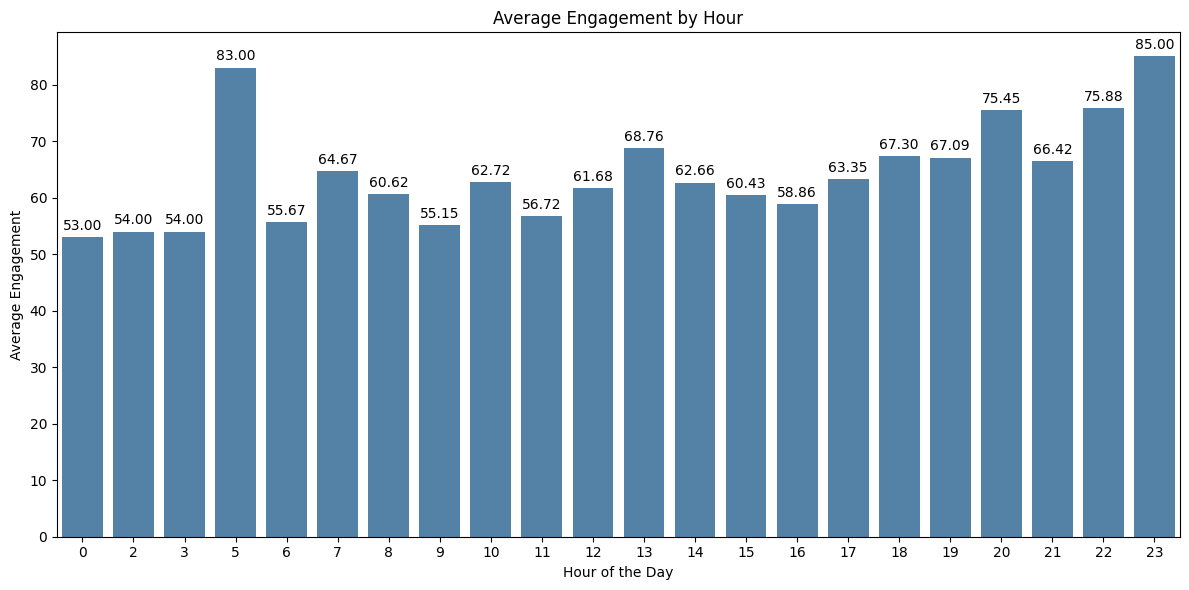

In [84]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=hourly_engagement.reset_index(),
    x='Hour',
    y='Average_Engagement',
    color='steelblue'
)

# add labels
for container in ax.containers:
  ax.bar_label(
      container,
      padding=3,
      fmt='%.2f'
  )

plt.title('Average Engagement by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Engagement')

plt.tight_layout()
plt.show()

### **Engagement by Day**

**Observations:**
- Highest engagement: The 13th day leads with 79.00 average engagement (7 posts), followed by the 4th day (72.00) and 2nd day (71.89).



- Lowest engagement: The 3rd day records the lowest average engagement at 54.80 (20 posts).



- Engagement fluctuations: Engagement fluctuates during the first half of the month, with a downward trend from the 16th to the 19th.



- Post volume vs. engagement: Higher post volume does not necessarily mean higher average engagement. For example, the 13th day has 7 posts but the highest average, while the 15th has 72 posts and an average of 68.07.



Additional insight: The 28th day also performs relatively well, with 70.17 average engagement across 58 posts.

In [74]:
# calculate average engagement per day
daily_engagement = data.groupby('Day').agg(
    Post_count=('Total Engagement', 'count'),
    Average_Engagement=('Total Engagement', 'mean')
)

# sort by day
daily_engagement = daily_engagement.sort_index()

# round average engagement to 2 decimal points
daily_engagement['Average_Engagement'] = daily_engagement['Average_Engagement'].round(2)

daily_engagement

,Post_count,Average_Engagement
Day,,
1,24,56.50
2,27,71.89
3,20,54.80
4,5,72.00
5,46,61.91
6,6,67.50
7,11,59.82
8,33,69.85
9,5,57.60


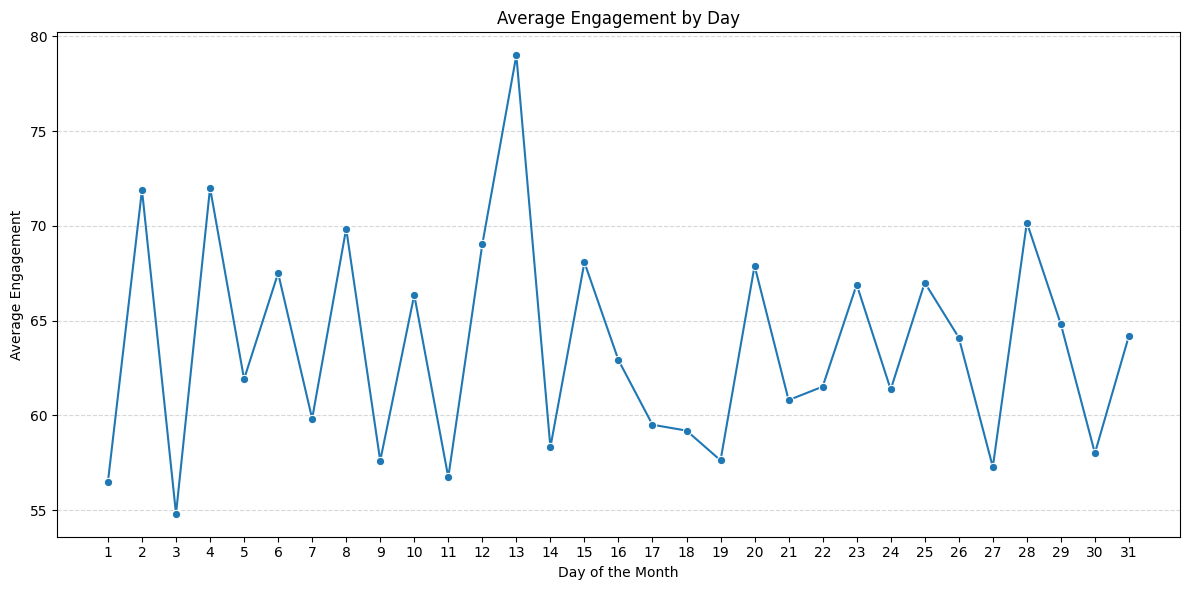

In [86]:
# plot line chart
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=daily_engagement.reset_index(),
    x='Day',
    y='Average_Engagement',
    marker='o'
)

plt.title('Average Engagement by Day')
plt.xlabel('Day of the Month')
plt.ylabel('Average Engagement')

plt.xticks(range(1, 32))
plt.grid(axis='y',
         linestyle='--',
         alpha=0.5
        )

plt.tight_layout()
plt.show()

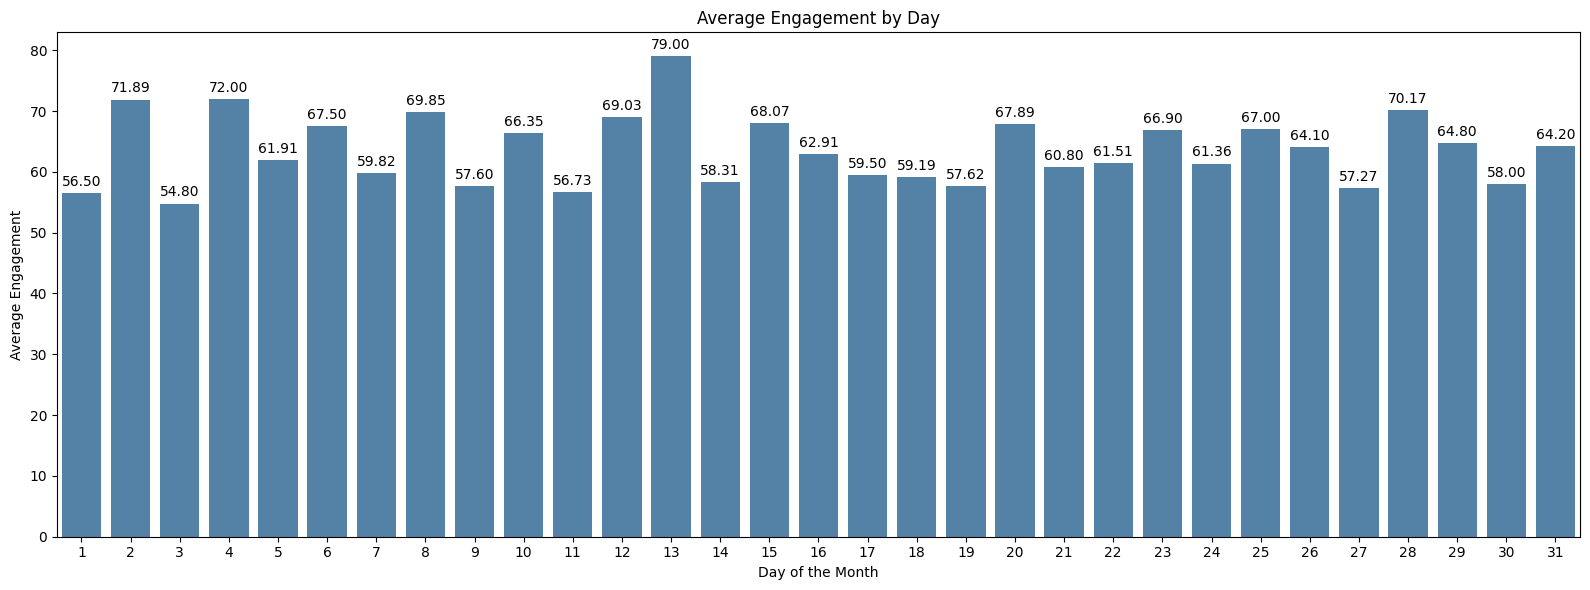

In [89]:
plt.figure(figsize=(16, 6))

ax = sns.barplot(
    data=daily_engagement.reset_index(),
    x='Day',
    y='Average_Engagement',
    color='steelblue'
)

# add labels
for container in ax.containers:
  ax.bar_label(
      container,
      padding=3,
      fmt='%.2f'
  )

plt.title('Average Engagement by Day')
plt.xlabel('Day of the Month')
plt.ylabel('Average Engagement')

plt.tight_layout()
plt.show()

### **Engagement by Month**

**Observations:**

- Highest engagement: July (Month 7) leads with 74.40 average engagement across 60 posts, followed by June (71.07) and August (65.91).



- Lowest engagement: January (Month 1) records the lowest average engagement at 56.88, despite having 78 posts.



- Engagement fluctuations: Average engagement rises from January (56.88) through April (64.18), declines in May (63.16), then peaks in July (74.40).



- Post volume vs. engagement: Higher post volume does not necessarily result in higher average engagement. February has the most posts (85), but its average engagement is only 61.86, while July has 60 posts and the highest average.

In [88]:
# calculate average engagement per month
monthly_engagement = data.groupby('Month').agg(
    Post_Count=('Total Engagement', 'count'),
    Average_Engagement=('Total Engagement', 'mean')
)

# sort by month
monthly_engagement= monthly_engagement.sort_index()

# round average engagement to 2 decimal places
monthly_engagement['Average_Engagement'] = monthly_engagement['Average_Engagement'].round(2)

monthly_engagement

,Post_Count,Average_Engagement
Month,,
1,78,56.88
2,85,61.86
3,44,63.91
4,49,64.18
5,45,63.16
6,70,71.07
7,60,74.40
8,75,65.91
9,74,62.61


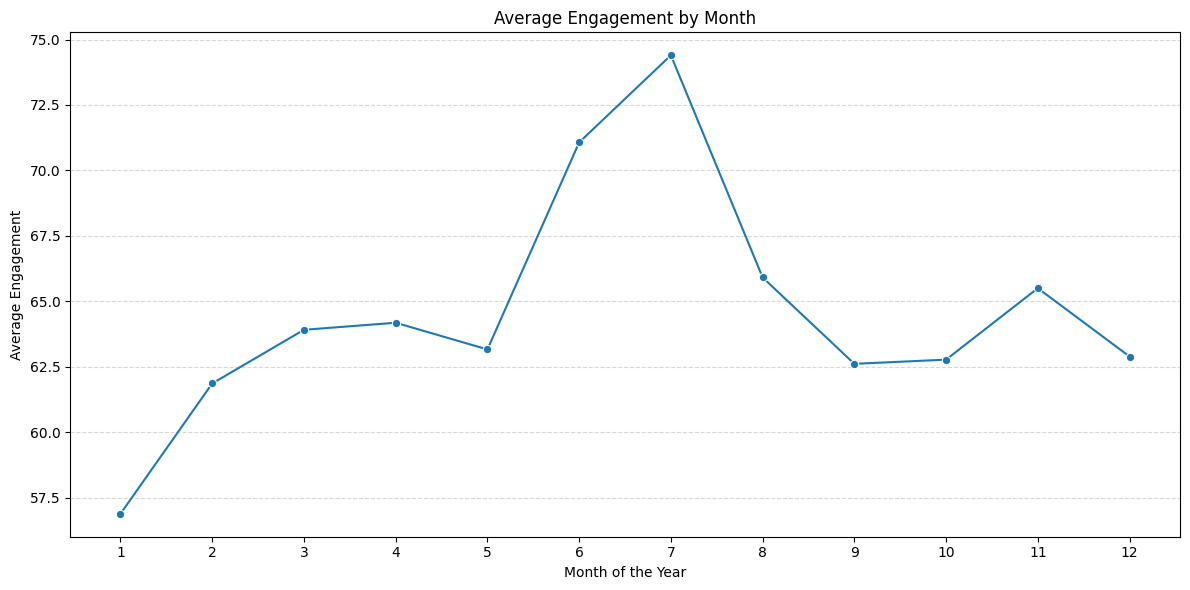

In [94]:
# plot line chart
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_engagement.reset_index(),
    x='Month',
    y='Average_Engagement',
    marker='o'
)

plt.title('Average Engagement by Month')
plt.xlabel('Month of the Year')
plt.ylabel('Average Engagement')

plt.xticks(range(1, 13))
plt.grid(axis='y',
         linestyle='--',
         alpha=0.5
        )

plt.tight_layout()
plt.show()

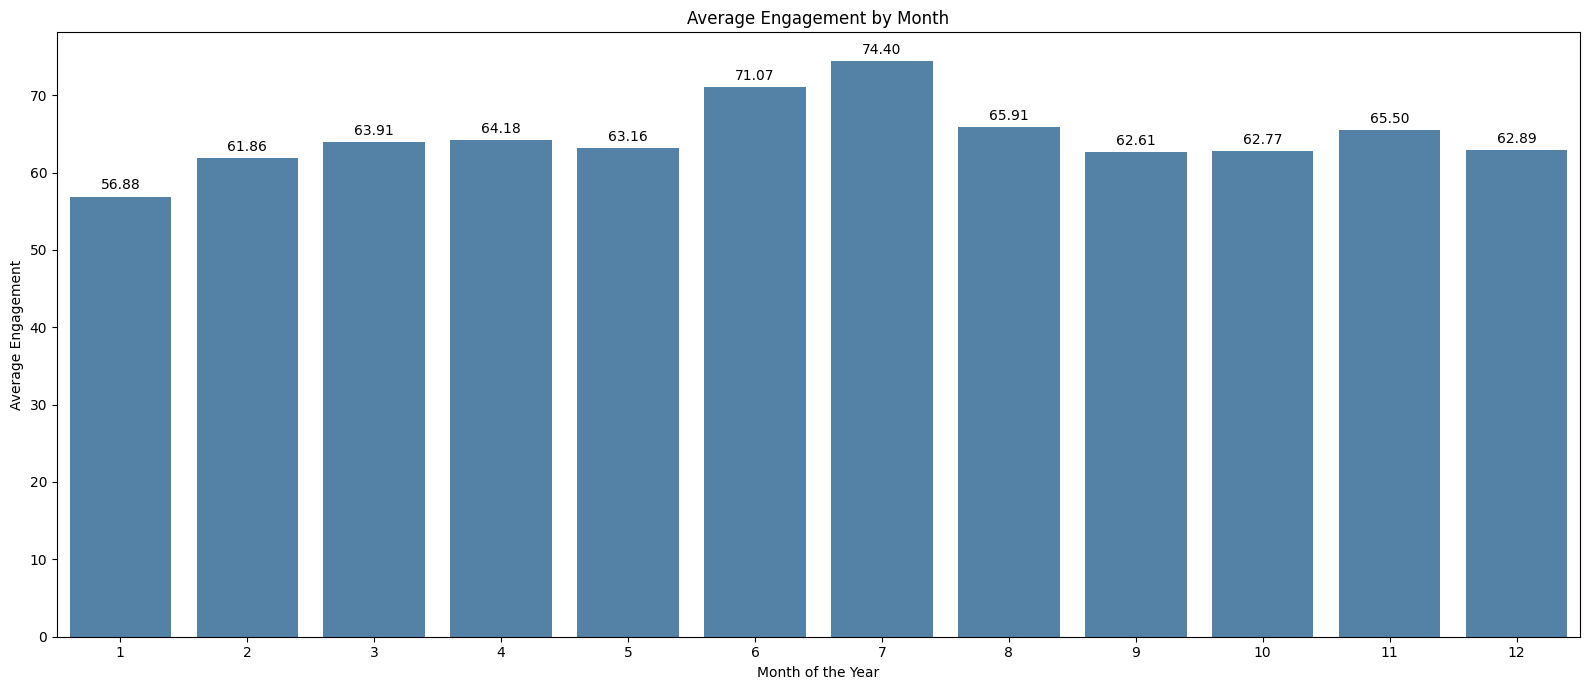

In [92]:
plt.figure(figsize=(16, 7))

ax = sns.barplot(
    data=monthly_engagement.reset_index(),
    x='Month',
    y='Average_Engagement',
    color='steelblue'
)

# add labels
for container in ax.containers:
  ax.bar_label(
      container,
      padding=3,
      fmt='%.2f'
  )

plt.title('Average Engagement by Month')
plt.xlabel('Month of the Year')
plt.ylabel('Average Engagement')

plt.tight_layout()
plt.show()